<a href="https://colab.research.google.com/github/gnuchessmen/physics-informed-neural-network-for-rapid-fluid-simulation/blob/main/Physics_Informed_Neural_Networks_for_rapid_Fluid_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Generating Data using Finite Element Methods

In [ ]:
# 1. Install FEniCSx via the official 'FEM on Colab' release script
try:
    import dolfinx
except ImportError:
    !wget "https://fem-on-colab.github.io/releases/fenicsx-install-release-real.sh" -O "/tmp/fenicsx-install.sh"
    !bash "/tmp/fenicsx-install.sh"
    import dolfinx

# 2. Install pygmsh, meshio for geometry handling, and matplotlib/pyvista for testing
!pip install pygmsh meshio matplotlib pyvista

--2026-07-21 10:20:35--  https://fem-on-colab.github.io/releases/fenicsx-install-release-real.sh
Resolving fem-on-colab.github.io (fem-on-colab.github.io)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to fem-on-colab.github.io (fem-on-colab.github.io)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4339 (4.2K) [application/x-sh]
Saving to: ‘/tmp/fenicsx-install.sh’

/tmp/fenicsx-instal 100%[===================>]   4.24K  --.-KB/s    in 0s      

2026-07-21 10:20:35 (33.6 MB/s) - ‘/tmp/fenicsx-install.sh’ saved [4339/4339]

+ INSTALL_PREFIX=/usr/local
++ echo /usr/local
++ awk -F/ '{print NF-1}'
+ INSTALL_PREFIX_DEPTH=2
+ PROJECT_NAME=fem-on-colab
+ SHARE_PREFIX=/usr/local/share/fem-on-colab
+ FENICSX_INSTALLED=/usr/local/share/fem-on-colab/fenicsx.installed
+ [[ ! -f /usr/local/share/fem-on-colab/fenicsx.installed ]]
+ PYBIND11_INSTALL_SCRIPT_PATH=https://github.com/fem-on-colab/fem-on-colab.github.io/raw/e12a85f2/release

In [ ]:
# Install missing system library for pygmsh/gmsh
!apt-get install -y libglu1-mesa

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  libglu1-mesa
0 upgraded, 1 newly installed, 0 to remove and 3 not upgraded.
Need to get 145 kB of archives.
After this operation, 367 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 libglu1-mesa amd64 9.0.2-1 [145 kB]
Fetched 145 kB in 1s (282 kB/s)
Selecting previously unselected package libglu1-mesa:amd64.
(Reading database ... 118243 files and directories currently installed.)
Preparing to unpack .../libglu1-mesa_9.0.2-1_amd64.deb ...
Unpacking libglu1-mesa:amd64 (9.0.2-1) ...
Setting up libglu1-mesa:amd64 (9.0.2-1) ...
Processing triggers for libc-bin (2.35-0ubuntu3.13) ...
/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symb

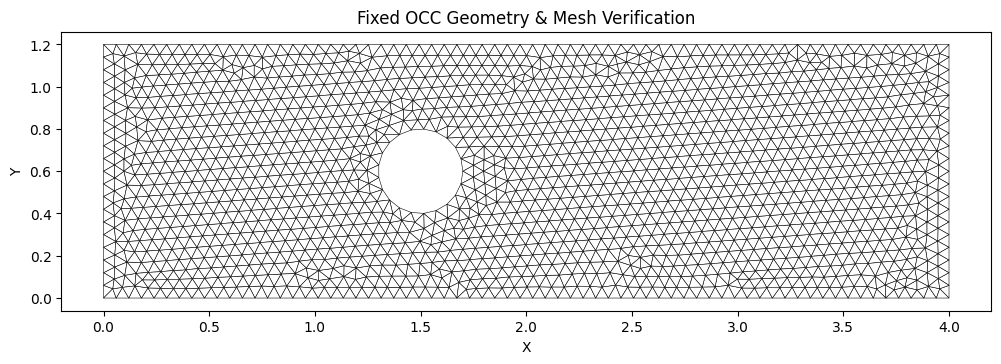

In [ ]:
import pygmsh
import meshio
import numpy as np
import matplotlib.pyplot as plt

D = 0.4
U_max = 1.5

# 1. Initialize the OpenCASCADE (OCC) kernel to support boolean subtraction
with pygmsh.occ.Geometry() as geom:
    # Set the global mesh scaling constraints for OpenCASCADE
    geom.characteristic_length_min = 0.015
    geom.characteristic_length_max = 0.060

    # 2. Add the outer rectangular channel
    # Arguments: [x_min, y_min, z_min], width, height
    channel = geom.add_rectangle([0.0, 0.0, 0.0], 4.0, 1.2)

    # 3. Add the obstacle (A disk)
    # Arguments: [x_center, y_center, z_center], radius
    obstacle = geom.add_disk([1.5, 0.6, 0.0], D/2)

    # 4. Perform the boolean subtraction (Channel minus Obstacle)
    fluid_domain = geom.boolean_difference(channel, obstacle)

    # Tag the physical surface for dolfinx identification
    geom.add_physical(fluid_domain, "fluid")

    # Compile the raw mesh structure using the OCC compiler
    raw_mesh = geom.generate_mesh()

# 5. Extract the pure 2D triangular cell arrays
triangles = raw_mesh.get_cells_type("triangle")
x, y = raw_mesh.points[:, 0], raw_mesh.points[:, 1]

# Immediate Visual Verification inside the Colab Notebook
plt.figure(figsize=(12, 5))
plt.tripcolor(x, y, triangles, facecolors=np.zeros(len(triangles)),
             edgecolors='k', cmap='binary', linewidth=0.4)
plt.gca().set_aspect('equal')
plt.title("Fixed OCC Geometry & Mesh Verification")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

# 6. Export clean 2D elements for dolfinx consumption
out_mesh = meshio.Mesh(points=raw_mesh.points[:, :2], cells={"triangle": triangles})
meshio.write("colab_mesh.xdmf", out_mesh)

In [ ]:
# For illustration, printing the first (x, y) coordinates
for _ in range(10):
    print(out_mesh.points[_])

[1.7 0.6]
[0. 0.]
[4. 0.]
[0.  1.2]
[4.  1.2]
[1.69111456 0.65895103]
[1.66524775 0.71266401]
[1.62469796 0.7563663 ]
[1.5730682  0.78617475]
[1.51494602 0.79944076]


In [ ]:
from mpi4py import MPI
from dolfinx.io import XDMFFile
from dolfinx.fem import functionspace
import ufl

# 1. Load the file created by meshio
with XDMFFile(MPI.COMM_WORLD, "colab_mesh.xdmf", "r") as xdmf:
    domain = xdmf.read_mesh(name="Grid")

print("--- FEniCSx Import Check ---")
print(f"Topology Dimension: {domain.topology.dim}D (Successfully read as structural surface)")
print(f"Number of mesh geometry nodes: {domain.geometry.x.shape[0]}")

# 2. Define a Vector Function Space
# The third item in the tuple (domain.geometry.dim,) turns a scalar space into a Vector space
V_space = functionspace(domain, ("Lagrange", 2, (domain.geometry.dim,)))

print(f"Degrees of freedom mapped successfully: {V_space.dofmap.index_map.size_global}")

--- FEniCSx Import Check ---
Topology Dimension: 2D (Successfully read as structural surface)
Number of mesh geometry nodes: 1659
Degrees of freedom mapped successfully: 6441


In [ ]:
import h5py

In [ ]:
import numpy as np
from mpi4py import MPI
from dolfinx.io import XDMFFile
from dolfinx.fem import functionspace, Function, dirichletbc, locate_dofs_topological, form, Constant, set_bc
from dolfinx.fem.petsc import assemble_matrix, assemble_vector, create_matrix, create_vector, apply_lifting
from dolfinx.mesh import locate_entities_boundary
import ufl
from petsc4py import PETSc

# 1. Physics & Simulation Parameters
dt = 0.001         # Time step size
T_final = 1.0      # Total simulation time
nu = D/18          # Kinematic viscosity (μ/ρ)

# 2. Reload Mesh & Create Taylor-Hood Function Spaces
with XDMFFile(MPI.COMM_WORLD, "colab_mesh.xdmf", "r") as xdmf:
    domain = xdmf.read_mesh(name="Grid")

# Velocity Space (P2 Quadratic Triangles)
V = functionspace(domain, ("Lagrange", 2, (domain.geometry.dim,)))
# Pressure Space (P1 Linear Triangles)
Q = functionspace(domain, ("Lagrange", 1))

# Extract coordinates directly from the Pressure Space (P1) to prevent DOF scrambling
pinn_coords = Q.tabulate_dof_coordinates()[:, :2]
num_nodes = pinn_coords.shape[0]

# Build a temporary P1 Vector Space to downsample P2 velocity values to P1 grid nodes
V_P1 = functionspace(domain, ("Lagrange", 1, (domain.geometry.dim,)))
u_next_P1 = Function(V_P1)

# Initialize data collection logs
time_history = []
velocity_history = []  # Will now store shape-aligned (P1) u_x and u_y fields
pressure_history = []  # Will store shape-aligned (P1) p field

print(f"PINN Data Logger initialized. Tracking {num_nodes} spatially synchronized grid nodes.")

# Extract coordinates exactly as they are ordered in the Pressure (P1) and Velocity (P2) memory arrays
pinn_coords_pressure = Q.tabulate_dof_coordinates()[:, :2]
pinn_coords_velocity = V.tabulate_dof_coordinates()[:, :2]

# 3. Define Boundary Conditions
# Inlet (Left boundary: x = 0)
inlet_facets = locate_entities_boundary(domain, 1, lambda x: np.isclose(x[0], 0.0))
inlet_dofs = locate_dofs_topological(V, 1, inlet_facets)
# Dynamic parabolic inlet velocity profile: max speed of 1.5 in x-direction
u_inlet = Function(V)
u_inlet.interpolate(lambda x: np.stack((4.0 * U_max * x[1] * (1.2 - x[1]) / 1.44, np.zeros_like(x[1]))))
bc_inlet = dirichletbc(u_inlet, inlet_dofs)

# Walls & Obstacle (No-Slip condition: u = 0 on top/bottom walls and internal obstacle)
# We find everything that is a boundary EXCEPT the inlet (x=0) and outlet (x=4)
wall_facets = locate_entities_boundary(domain, 1, lambda x: ~np.isclose(x[0], 0.0) & ~np.isclose(x[0], 4.0))
wall_dofs = locate_dofs_topological(V, 1, wall_facets)
u_zero = Function(V) # Defaults to 0.0
bc_walls = dirichletbc(u_zero, wall_dofs)

# Outlet (Right boundary: x = 4, fix pressure p = 0)
outlet_facets = locate_entities_boundary(domain, 1, lambda x: np.isclose(x[0], 4.0))
outlet_dofs = locate_dofs_topological(Q, 1, outlet_facets)
p_zero = Function(Q)
bc_outlet = dirichletbc(p_zero, outlet_dofs)

bcs_u = [bc_inlet, bc_walls]
bcs_p = [bc_outlet]

# 4. Declare Variational Forms (The FEM Weak Formulations)
u, v = ufl.TrialFunction(V), ufl.TestFunction(V)
p, q = ufl.TrialFunction(Q), ufl.TestFunction(Q)

# Functions to hold solutions at current and previous steps
u_n = Function(V)  # Velocity at t_n
u_  = Function(V)  # Predicted velocity u*
u_next = Function(V) # Corrected velocity u_(n+1)
p_n = Function(Q)  # Pressure at t_n
p_next = Function(Q) # Corrected pressure p_(n+1)

# Constants wrapped for UFL execution
k = Constant(domain, PETSc.ScalarType(dt))
nu_const = Constant(domain, PETSc.ScalarType(nu))

# --- STEP 1 FORM: Tentative Velocity (u*) ---
F1 = (1.0/k) * ufl.dot(u - u_n, v) * ufl.dx \
     + ufl.dot(ufl.dot(u_n, ufl.nabla_grad(u_n)), v) * ufl.dx \
     + 0.5 * nu_const * ufl.inner(ufl.grad(u + u_n), ufl.grad(v)) * ufl.dx \
     + ufl.dot(ufl.grad(p_n), v) * ufl.dx
a1, L1 = form(ufl.lhs(F1)), form(ufl.rhs(F1))

# --- STEP 2 FORM: Pressure Correction (p_next) ---
F2 = ufl.dot(ufl.grad(p), ufl.grad(q)) * ufl.dx \
     - ufl.dot(ufl.grad(p_n), ufl.grad(q)) * ufl.dx \
     + (1.0/k) * ufl.div(u_) * q * ufl.dx
a2, L2 = form(ufl.lhs(F2)), form(ufl.rhs(F2))

# --- STEP 3 FORM: Velocity Correction (u_next) ---
F3 = ufl.dot(u, v) * ufl.dx - ufl.dot(u_, v) * ufl.dx \
     + k * ufl.dot(ufl.grad(p_next - p_n), v) * ufl.dx
a3, L3 = form(ufl.lhs(F3)), form(ufl.rhs(F3))

# 5. Pre-assemble Stiffness Matrices for Performance
A1 = create_matrix(a1)
assemble_matrix(A1, a1, bcs=bcs_u)
A1.assemble()

A2 = create_matrix(a2)
assemble_matrix(A2, a2, bcs=bcs_p)
A2.assemble()

A3 = create_matrix(a3)
assemble_matrix(A3, a3, bcs=bcs_u)
A3.assemble()

b1 = create_vector(V)  # Step 1 predicts Velocity, so it matches space V
b2 = create_vector(Q)  # Step 2 corrects Pressure, so it matches space Q
b3 = create_vector(V)  # Step 3 corrects Velocity, so it matches space V


# Setup PETSc linear solvers
# Use highly robust Direct Solvers (LU) to prevent algebraic divergence
solver_u = PETSc.KSP().create(domain.comm)
solver_u.setType(PETSc.KSP.Type.PREONLY)
solver_u.getPC().setType(PETSc.PC.Type.LU)

solver_p = PETSc.KSP().create(domain.comm)
solver_p.setType(PETSc.KSP.Type.PREONLY)
solver_p.getPC().setType(PETSc.PC.Type.LU)

# Force-reset all computational fields back to 0.0 before launching the time loop
u_n.x.array[:] = 0.0
u_.x.array[:] = 0.0
u_next.x.array[:] = 0.0
p_n.x.array[:] = 0.0
p_next.x.array[:] = 0.0

# 6. The Real-Time Simulation Execution Loop
t = 0.0
print("Beginning time-stepping fluid solver engine...")

while t < T_final:
    t += dt

    # --- Step 1: Predict tentative velocity ---
    with b1.localForm() as loc:
        loc.set(0)
    assemble_vector(b1, L1)

    # 1. Lift the non-zero boundary conditions into the interior equations
    apply_lifting(b1, [a1], [bcs_u])
    # 2. Update ghost nodes across the vector structure
    b1.ghostUpdate(addv=PETSc.InsertMode.ADD_VALUES, mode=PETSc.ScatterMode.REVERSE)
    # 3. Forcefully apply the exact boundary values
    set_bc(b1, bcs_u)

    solver_u.setOperators(A1)
    solver_u.solve(b1, u_.x.petsc_vec)
    u_.x.scatter_forward()


    # --- Step 2: Solve for corrected pressure ---
    with b2.localForm() as loc:
        loc.set(0)
    assemble_vector(b2, L2)

    apply_lifting(b2, [a2], [bcs_p])
    b2.ghostUpdate(addv=PETSc.InsertMode.ADD_VALUES, mode=PETSc.ScatterMode.REVERSE)
    set_bc(b2, bcs_p)

    solver_p.setOperators(A2)
    solver_p.solve(b2, p_next.x.petsc_vec)
    p_next.x.scatter_forward()


    # --- Step 3: Correct the velocity field ---
    with b3.localForm() as loc:
        loc.set(0)
    assemble_vector(b3, L3)

    apply_lifting(b3, [a3], [bcs_u])
    b3.ghostUpdate(addv=PETSc.InsertMode.ADD_VALUES, mode=PETSc.ScatterMode.REVERSE)
    set_bc(b3, bcs_u)

    solver_u.setOperators(A3)
    solver_u.solve(b3, u_next.x.petsc_vec)
    u_next.x.scatter_forward()

    # Progress Update
    if np.isclose(t % 0.2, 0) or np.isclose(t, T_final):
        max_vel = np.max(u_next.x.array)
        print(f"Time: {t:.2f}s | Max Domain Velocity Vector: {max_vel:.4f}")

    # Move to next step (update states)
    u_n.x.array[:] = u_next.x.array
    p_n.x.array[:] = p_next.x.array

    # --- DEEP MULTI-LAYER PINN DATA SAMPLING ---
    # Move to next step (update states)
    u_n.x.array[:] = u_next.x.array
    p_n.x.array[:] = p_next.x.array

    # --- SYNCHRONIZED PINN DATA SAMPLING ---
    time_history.append(t)

    # 1. Project the quadratic P2 velocity function onto the linear P1 vector space
    u_next_P1.interpolate(u_next)

    # 2. Extract decoupled NumPy arrays for the velocity components
    raw_vel_data = np.array(u_next_P1.x.array, copy=True)
    current_vel = raw_vel_data.reshape(-1, domain.geometry.dim)[:, :2]
    velocity_history.append(current_vel)

    # 3. Extract decoupled NumPy arrays for the pressure field
    raw_pres_data = np.array(p_next.x.array, copy=True)
    current_pres = raw_pres_data[:num_nodes]
    pressure_history.append(current_pres)

print("Simulation Engine finished successfully! Fluid profiles computed.")

PINN Data Logger initialized. Tracking 1659 spatially synchronized grid nodes.
Beginning time-stepping fluid solver engine...
Time: 0.20s | Max Domain Velocity Vector: 2.0761
Time: 0.40s | Max Domain Velocity Vector: 2.1256
Time: 0.60s | Max Domain Velocity Vector: 2.1352
Time: 0.80s | Max Domain Velocity Vector: 2.1389
Time: 1.00s | Max Domain Velocity Vector: 2.1426
Simulation Engine finished successfully! Fluid profiles computed.


In [ ]:
# Save out to a clean deep-learning ready HDF5 file structure (Dimensional Baseline)
t_array = np.array(time_history)
u_array = np.array(velocity_history)
p_array = np.array(pressure_history)

with h5py.File("pinn_training_data.h5", "w") as f:
    f.create_dataset("coordinates", data=pinn_coords, compression="gzip")
    f.create_dataset("time", data=t_array, compression="gzip")
    f.create_dataset("velocity", data=u_array, compression="gzip")
    f.create_dataset("pressure", data=p_array, compression="gzip")

print("Dimensional standard file 'pinn_training_data.h5' compiled successfully!")

# --- Execute Nondimensionalization Scaling ---
L_c = D   # Cylinder diameter (m)
U_c = (2.0 / 3.0) * U_max  # Characteristic Mean Velocity (1.0 m/s)
T_c = L_c / U_c  # Characteristic Time scale (seconds)
current_Re = (U_c * L_c) / nu

pinn_coords_tilde = pinn_coords / L_c
t_array_tilde = t_array / T_c
u_array_tilde = u_array / U_c
p_array_tilde = p_array / (U_c**2)

# --- Compile into a Parametric, Dimensionless HDF5 Database ---
filename = "dimensionless_pinn_dataset.h5"

with h5py.File(filename, "a") as f:
    run_name = f"run_Re_{int(round(current_Re))}"
    if run_name in f:
        del f[run_name]

    run_group = f.create_group(run_name)

    # Store dynamic metadata scales as attributes
    run_group.attrs["characteristic_length"] = L_c
    run_group.attrs["characteristic_velocity"] = U_c
    run_group.attrs["characteristic_time"] = T_c
    run_group.attrs["kinematic_viscosity"] = nu
    run_group.attrs["reynolds_number"] = current_Re

    # Save aligned tensors on a single spatial grid framework
    run_group.create_dataset("coordinates", data=pinn_coords_tilde, compression="gzip")
    run_group.create_dataset("time", data=t_array_tilde, compression="gzip")
    run_group.create_dataset("velocity", data=u_array_tilde, compression="gzip")
    run_group.create_dataset("pressure", data=p_array_tilde, compression="gzip")

print(f"Data scaled and logged! Group '{run_name}' compiled successfully into {filename}.")

Dimensional standard file 'pinn_training_data.h5' compiled successfully!
Data scaled and logged! Group 'run_Re_18' compiled successfully into dimensionless_pinn_dataset.h5.


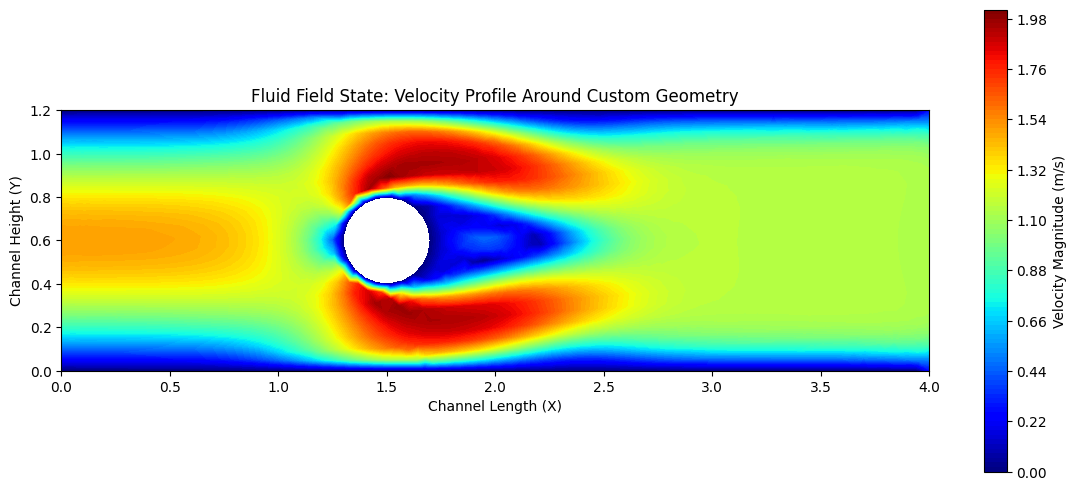

In [ ]:
import matplotlib.pyplot as plt
from dolfinx.fem import Expression, Function, functionspace
import ufl

# 1. Create a scalar function space to hold the calculated velocity magnitudes
Q_magnitude = functionspace(domain, ("Lagrange", 1))

# Access the property directly as an array
points = Q_magnitude.element.interpolation_points

# Pass the expression and the raw coordinate array
expr = Expression(ufl.sqrt(ufl.dot(u_next, u_next)), points)

magnitude_field = Function(Q_magnitude)
magnitude_field.interpolate(expr)

# 2. Extract point positions and mapping arrays for matplotlib
x_coords = domain.geometry.x[:, 0]
y_coords = domain.geometry.x[:, 1]

# Topology extraction for triangle connectivity
num_cells = domain.topology.index_map(2).size_local
triangles = domain.topology.connectivity(2, 0).array.reshape(num_cells, 3)
values = magnitude_field.x.array[:len(x_coords)]

# 3. Render the spatial fluid contour plot
plt.figure(figsize=(14, 6))
contour = plt.tricontourf(x_coords, y_coords, triangles, values, levels=100, cmap="jet")
plt.colorbar(contour, label="Velocity Magnitude (m/s)")

plt.gca().set_aspect('equal')
plt.title("Fluid Field State: Velocity Profile Around Custom Geometry")
plt.xlabel("Channel Length (X)")
plt.ylabel("Channel Height (Y)")
plt.show()

In [ ]:
def plot_velocity_at_time(target_time):
    """
    Finds the closest recorded historical frame to target_time,
    populates the aligned P1 function space buffers, and draws a 2D velocity contour.
    """
    time_diffs = np.abs(t_array - target_time)
    closest_idx = np.argmin(time_diffs)
    actual_time = t_array[closest_idx]

    print(f"Requested time: {target_time}s | Plotting closest available frame at: {actual_time:.4f}s")

    # Map directly to a P1 function container since u_array contains P1 velocities
    u_plot = Function(V_P1)
    u_plot.x.array[:] = u_array[closest_idx].flatten()
    u_plot.x.scatter_forward()

    # Calculate velocity magnitude mapping using the P1 function field
    Q_mag = functionspace(domain, ("Lagrange", 1))
    expr_mag = Expression(ufl.sqrt(ufl.dot(u_plot, u_plot)), Q_mag.element.interpolation_points)
    mag_field = Function(Q_mag)
    mag_field.interpolate(expr_mag)

    x_c = domain.geometry.x[:, 0]
    y_c = domain.geometry.x[:, 1]
    n_c = domain.topology.index_map(2).size_local
    tri = domain.topology.connectivity(2, 0).array.reshape(n_c, 3)
    vals = mag_field.x.array[:len(x_c)]

    plt.figure(figsize=(14, 6))
    contour_plot = plt.tricontourf(x_c, y_c, tri, vals, levels=100, cmap="jet")
    plt.colorbar(contour_plot, label="Velocity Magnitude (m/s)")
    plt.gca().set_aspect('equal')
    plt.title(f"Fluid Field State: Velocity Profile at t = {actual_time:.3f}s")
    plt.xlabel("Channel Length (X)")
    plt.ylabel("Channel Height (Y)")
    plt.show()

Requested time: 0.5s | Plotting closest available frame at: 0.5000s


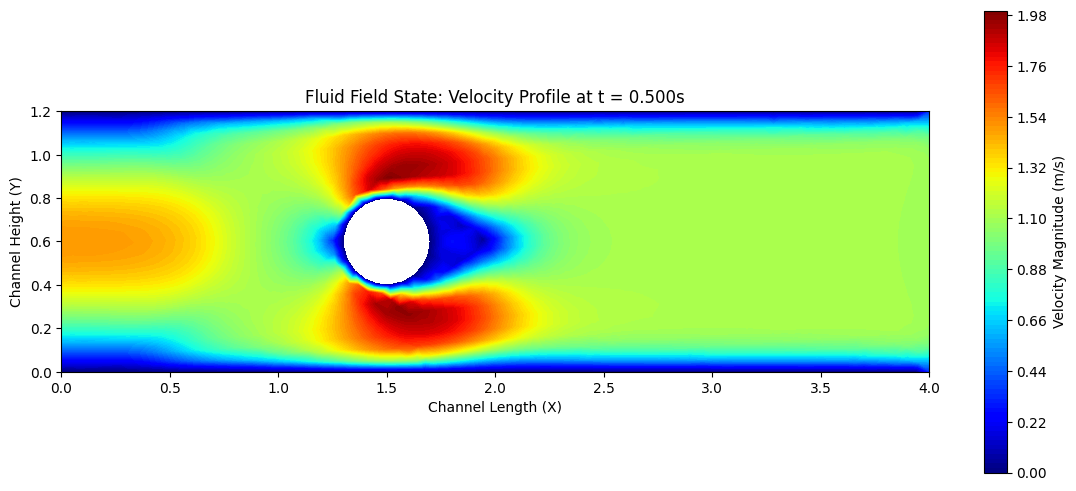

In [ ]:
# View the initial wave formation phase shortly after launching
plot_velocity_at_time(0.5)

# Training the Physics Informed Neural Networks (PINNs)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset
import h5py
import numpy as np
import time

In [ ]:
# ==============================================================================
# 1. OPTIMIZED DATASET (Pre-loads entirely into GPU VRAM with Z-Score Scaling)
# ==============================================================================
class ParametricPINNDataset:
    def __init__(self, h5_filepath, device):
        print(f"Loading {h5_filepath} and migrating directly to {device} VRAM...")

        X_all, Y_all = [], []

        with h5py.File(h5_filepath, "r") as f:
            for group_name in f.keys():
                group = f[group_name]
                Re = group.attrs["reynolds_number"]

                coords = group["coordinates"][:]  # (N, 2)
                times = group["time"][:]          # (T,)
                vels = group["velocity"][:]       # (T, N, 2)
                press = group["pressure"][:]      # (T, N)

                T, N = vels.shape[0], vels.shape[1]

                coords_tiled = np.tile(coords, (T, 1))
                times_repeated = np.repeat(times, N).reshape(-1, 1)
                re_array = np.full((T * N, 1), Re)

                X_group = np.hstack((coords_tiled, times_repeated, re_array))
                vels_flat = vels.reshape(-1, 2)
                press_flat = press.reshape(-1, 1)
                Y_group = np.hstack((vels_flat, press_flat))

                X_all.append(X_group)
                Y_all.append(Y_group)

        # Convert to tensors
        X_raw = torch.tensor(np.vstack(X_all), dtype=torch.float32)
        Y_raw = torch.tensor(np.vstack(Y_all), dtype=torch.float32)

        # Calculate Standardization Statistics (Mean & Std)
        self.X_mean = X_raw.mean(dim=0).to(device)
        self.X_std = X_raw.std(dim=0).to(device)
        self.Y_mean = Y_raw.mean(dim=0).to(device)
        self.Y_std = Y_raw.std(dim=0).to(device)

        # Prevent division by zero for constant arrays
        self.X_std[self.X_std == 0] = 1.0
        self.Y_std[self.Y_std == 0] = 1.0

        # Normalize and push entire dataset instantly to GPU
        self.X = ((X_raw.to(device) - self.X_mean) / self.X_std)
        self.Y = ((Y_raw.to(device) - self.Y_mean) / self.Y_std)

        self.num_samples = self.X.shape[0]
        print(f"Dataset fully loaded and standardized! Total points: {self.num_samples:,}")

In [ ]:
# ==============================================================================
# 2. NEURAL NETWORK ARCHITECTURE
# ==============================================================================
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.linears = nn.ModuleList()
        for i in range(len(layers) - 1):
            self.linears.append(nn.Linear(layers[i], layers[i+1]))
        self.activation = nn.Tanh()

    def forward(self, x):
        for i in range(len(self.linears) - 1):
            x = self.activation(self.linears[i](x))
        x = self.linears[-1](x)
        return x

In [ ]:
# ==============================================================================
# 3. PHYSICS LOSS FUNCTION (Dimensionless Navier-Stokes)
# ==============================================================================
def compute_physics_loss(model, X_batch, dataset):
    """
    Computes NS residuals. X_batch is normalized. We must apply the chain rule
    using the dataset's standard deviations to get accurate physical gradients.
    """
    # 1. Forward Pass
    Y_pred_norm = model(X_batch)

    # 2. Un-normalize the predictions back to physical dimensionless values
    u = Y_pred_norm[:, 0:1] * dataset.Y_std[0] + dataset.Y_mean[0]
    v = Y_pred_norm[:, 1:2] * dataset.Y_std[1] + dataset.Y_mean[1]
    p = Y_pred_norm[:, 2:3] * dataset.Y_std[2] + dataset.Y_mean[2]

    # Extract the un-normalized Re directly from the batch for the viscosity term
    Re = X_batch[:, 3:4] * dataset.X_std[3] + dataset.X_mean[3]

    # 3. First-Order Gradients via Autograd
    # autograd.grad calculates wrt normalized X_batch: [x_norm, y_norm, t_norm, Re_norm]
    grad_outputs = torch.ones_like(u)

    u_grads = torch.autograd.grad(u, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]
    v_grads = torch.autograd.grad(v, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]
    p_grads = torch.autograd.grad(p, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]

    # Apply Chain Rule: d/dx_real = (d/dx_norm) * (1 / std_x)
    u_x = u_grads[:, 0:1] / dataset.X_std[0]
    u_y = u_grads[:, 1:2] / dataset.X_std[1]
    u_t = u_grads[:, 2:3] / dataset.X_std[2]

    v_x = v_grads[:, 0:1] / dataset.X_std[0]
    v_y = v_grads[:, 1:2] / dataset.X_std[1]
    v_t = v_grads[:, 2:3] / dataset.X_std[2]

    p_x = p_grads[:, 0:1] / dataset.X_std[0]
    p_y = p_grads[:, 1:2] / dataset.X_std[1]

    # 4. Second-Order Gradients
    u_x_grads = torch.autograd.grad(u_x, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]
    u_y_grads = torch.autograd.grad(u_y, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]
    v_x_grads = torch.autograd.grad(v_x, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]
    v_y_grads = torch.autograd.grad(v_y, X_batch, grad_outputs=grad_outputs, create_graph=True)[0]

    u_xx = u_x_grads[:, 0:1] / dataset.X_std[0]
    u_yy = u_y_grads[:, 1:2] / dataset.X_std[1]
    v_xx = v_x_grads[:, 0:1] / dataset.X_std[0]
    v_yy = v_y_grads[:, 1:2] / dataset.X_std[1]

    # 5. Compile the Navier-Stokes Residuals
    # Continuity: du/dx + dv/dy = 0
    f_c = u_x + v_y

    # Momentum X: u_t + u*u_x + v*u_y + p_x - (1/Re)*(u_xx + u_yy) = 0
    f_u = u_t + (u * u_x) + (v * u_y) + p_x - (1.0 / Re) * (u_xx + u_yy)

    # Momentum Y: v_t + u*v_x + v*v_y + p_y - (1/Re)*(v_xx + v_yy) = 0
    f_v = v_t + (u * v_x) + (v * v_y) + p_y - (1.0 / Re) * (v_xx + v_yy)

    # Total Physics Loss (MSE of residuals against zero)
    loss_physics = torch.mean(f_c**2) + torch.mean(f_u**2) + torch.mean(f_v**2)
    return loss_physics

In [ ]:
# ==============================================================================
# 4. MODULAR TRAINING LOOP (Optimized)
# ==============================================================================
def train_pinn(hyperparams, model=None):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training deployed on: {device}")

    # Dataset initializes straight into VRAM
    dataset = ParametricPINNDataset(hyperparams["data_path"], device)

    # IF NO MODEL IS PASSED, CREATE A NEW ONE. OTHERWISE, CONTINUE WITH THE PASSED MODEL.
    if model is None:
        print("Initializing a fresh PINN architecture...")
        model = PINN(hyperparams["layers"]).to(device)
    else:
        print("Continuing training with the provided model checkpoint...")
        model = model.to(device)

    # Swapped to AdamW for better deep-layer gradient stability
    optimizer = optim.AdamW(model.parameters(), lr=hyperparams["learning_rate"], weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    # Modern AMP syntax
    scaler = torch.amp.GradScaler('cuda', enabled=hyperparams["use_amp"])
    loss_fn = nn.MSELoss()

    batch_size = hyperparams["batch_size"]
    num_samples = dataset.num_samples

    print("\n--- Beginning Training ---")

    for epoch in range(1, hyperparams["epochs"] + 1):
        epoch_start_time = time.time()
        running_loss = 0.0

        # Native GPU Batching (Generates a shuffled index array directly in VRAM)
        permutation = torch.randperm(num_samples, device=device)

        for i in range(0, num_samples, batch_size):
            indices = permutation[i : i + batch_size]
            X_batch, Y_batch = dataset.X[indices], dataset.Y[indices]

            # Enable grad tracking only if calculating physics
            X_batch.requires_grad_(hyperparams["train_physics"])

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda', enabled=hyperparams["use_amp"]):
                Y_pred = model(X_batch)

                # 1. Data Loss (MSE on normalized space)
                loss_data = loss_fn(Y_pred, Y_batch)
                loss = loss_data

                # 2. Physics Loss
                if hyperparams["train_physics"]:
                    loss_physics = compute_physics_loss(model, X_batch, dataset)
                    loss = loss_data + (hyperparams["physics_weight"] * loss_physics)

            # Backward pass
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * X_batch.size(0)

        # Epoch metrics
        avg_loss = running_loss / num_samples
        scheduler.step(avg_loss)
        epoch_time = time.time() - epoch_start_time

        print(f"Epoch {epoch:03d}/{hyperparams['epochs']} | "
              f"Loss: {avg_loss:.6f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
              f"Time: {epoch_time:.2f}s")
    return model

In [ ]:
# ==============================================================================
# 5a. EXECUTION CONTROL
# ==============================================================================
hyperparameters = {
    "data_path": "dimensionless_pinn_dataset.h5",
    "layers": [4, 256, 256, 256, 256, 256, 256, 3],
    "epochs": 50,
    "batch_size": 16384,
    "learning_rate": 1e-3,
    "use_amp": True,
    "train_physics": False,  # Keep this false for Phase 1 pre-training
    "physics_weight": 0.1
}

In [ ]:
model = train_pinn(hyperparameters, model=None)

torch.save(model.state_dict(), "pinn_pretrained_data_only.pth")
print("Pre-trained weights saved successfully out of function scope!")

Training deployed on: cuda
Loading dimensionless_pinn_dataset.h5 and migrating directly to cuda VRAM...
Dataset fully loaded and standardized! Total points: 9,954,000
Initializing a fresh PINN architecture...

--- Beginning Training ---
Epoch 001/50 | Loss: 0.546720 | LR: 1.00e-03 | Time: 3.24s
Epoch 002/50 | Loss: 0.372731 | LR: 1.00e-03 | Time: 2.36s
Epoch 003/50 | Loss: 0.345885 | LR: 1.00e-03 | Time: 2.29s
Epoch 004/50 | Loss: 0.331169 | LR: 1.00e-03 | Time: 2.29s
Epoch 005/50 | Loss: 0.317473 | LR: 1.00e-03 | Time: 2.31s
Epoch 006/50 | Loss: 0.310242 | LR: 1.00e-03 | Time: 2.27s
Epoch 007/50 | Loss: 0.301877 | LR: 1.00e-03 | Time: 2.29s
Epoch 008/50 | Loss: 0.291528 | LR: 1.00e-03 | Time: 2.33s
Epoch 009/50 | Loss: 0.309104 | LR: 1.00e-03 | Time: 2.32s
Epoch 010/50 | Loss: 0.295818 | LR: 1.00e-03 | Time: 2.41s
Epoch 011/50 | Loss: 0.288959 | LR: 1.00e-03 | Time: 2.34s
Epoch 012/50 | Loss: 0.289229 | LR: 1.00e-03 | Time: 2.33s
Epoch 013/50 | Loss: 0.290161 | LR: 1.00e-03 | Time: 2.

In [ ]:
# ==============================================================================
# 5b. EXECUTION CONTROL
# ==============================================================================
hyperparameters_phase2 = {
    "data_path": "dimensionless_pinn_dataset.h5",
    "layers": [4, 256, 256, 256, 256, 256, 256, 3],
    "epochs": 100,
    "batch_size": 16384,
    "learning_rate": 1e-4,
    "use_amp": False,
    "train_physics": True,  # Keep this true for Phase 2 pre-training
    "physics_weight": 0.05
}

In [ ]:
# 1. Re-instantiate the Model Architecture Shell
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_phase2 = PINN(hyperparameters_phase2["layers"]).to(device)

# 2. Load the Pre-Trained Weights from disk
checkpoint_path = "pinn_pretrained_data_only.pth"
try:
    # map_location ensures it loads cleanly regardless of original saving device
    model_phase2.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"Successfully loaded pre-trained baseline from '{checkpoint_path}'!")
except FileNotFoundError:
    print(f"Error: '{checkpoint_path}' not found. Make sure you saved Phase 1 weights first.")

# 3. Launch the Training Loop passing the pre-loaded model instance
model_phase2 = train_pinn(hyperparameters_phase2, model=model_phase2)

# 4. Save the final fully Physics-Informed Neural Network
torch.save(model_phase2.state_dict(), "parametric_pinn_final.pth")
print("\nFinal parametric physics-informed model weights safely saved to disk!")

Successfully loaded pre-trained baseline from 'pinn_pretrained_data_only.pth'!
Training deployed on: cuda
Loading dimensionless_pinn_dataset.h5 and migrating directly to cuda VRAM...
Dataset fully loaded and standardized! Total points: 9,954,000
Continuing training with the provided model checkpoint...

--- Beginning Training ---
Epoch 001/100 | Loss: 4.650887 | LR: 1.00e-04 | Time: 89.54s
Epoch 002/100 | Loss: 0.926084 | LR: 1.00e-04 | Time: 90.37s
Epoch 003/100 | Loss: 0.643876 | LR: 1.00e-04 | Time: 90.52s
Epoch 004/100 | Loss: 0.540717 | LR: 1.00e-04 | Time: 90.56s
Epoch 005/100 | Loss: 0.492490 | LR: 1.00e-04 | Time: 90.48s
Epoch 006/100 | Loss: 0.462560 | LR: 1.00e-04 | Time: 90.54s
Epoch 007/100 | Loss: 0.444497 | LR: 1.00e-04 | Time: 90.54s
Epoch 008/100 | Loss: 1.418938 | LR: 1.00e-04 | Time: 90.51s
Epoch 009/100 | Loss: 0.631953 | LR: 1.00e-04 | Time: 90.51s
Epoch 010/100 | Loss: 0.551821 | LR: 1.00e-04 | Time: 90.50s
Epoch 011/100 | Loss: 0.510482 | LR: 1.00e-04 | Time: 90.4

In [ ]:
import torch
import gc

# 1. Clear out Python's references to dead data structures
gc.collect()

# 2. Force CUDA to release its cached memory allocations back to the system
torch.cuda.empty_cache()

# 3. Print out a status check to verify the available VRAM footprint
allocated = torch.cuda.memory_allocated() / (1024 ** 3)
reserved = torch.cuda.memory_reserved() / (1024 ** 3)
print(f"CUDA Clean Complete!")
print(f"Current Allocated VRAM: {allocated:.2f} GB")
print(f"Current Reserved VRAM:  {reserved:.2f} GB")

CUDA Clean Complete!
Current Allocated VRAM: 3.24 GB
Current Reserved VRAM:  3.37 GB
